# A/B Test Analysis: Did the Advertisement Increase Conversion?

## Business Problem

A marketing company ran an experiment to test whether showing an **advertisement (ad)**
increases product conversion compared to showing a neutral **Public Service Announcement (PSA)**.

The PSA group acts as the **control group** — they see a message of the same size and
placement, but it does not promote the product. This isolates the effect of the ad itself.

## Business Question

**Did the ad group convert at a significantly higher rate than the PSA group?**

## Success Metric

Conversion rate = (number of converted users) / (total users in group)

## Decision

If the ad significantly increases conversion, we recommend rollout.
Otherwise, we recommend keeping the PSA or running further tests.

## Step 1 — Import Libraries

We use pandas for data handling, matplotlib for charts, scipy for statistical tests,
and statsmodels for the Z-test and power analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.power import NormalIndPower

Bad value in file WindowsPath('C:/Users/onlys/anaconda3/Lib/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle'), line 162 ('mathtext.default: normal  # The default font to use for math.'): Key mathtext.default: 'normal' is not a valid value for mathtext.default; supported values are ['rm', 'cal', 'bfit', 'it', 'tt', 'sf', 'bf', 'default', 'bb', 'frak', 'scr', 'regular']

Bad key axes3d.depthshade in file C:\Users\onlys\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle, line 225 ('axes3d.depthshade   : False   # depth shade for 3D scatter plots')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.10.0/lib/matplotlib/mpl-data/matplotlibrc
or from the matplotlib source distribution

Bad key axes3d.depthshade_minalpha in file C:\Users\onlys\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle, line 226 ('axes3d.depthshade_minalpha : 0.3  # minimum alpha value for depth shading')


## Step 2 — Load the Dataset

The dataset has one row per user. Each row records which group the user was in
and whether they converted.

In [2]:
df = pd.read_csv("marketing_AB.csv")

print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (588101, 7)


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## Step 3 — Basic Data Check

Before any analysis, we check for missing values, duplicates, and how many users
are in each group.

In [3]:
print("Column types and non-null counts:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())


print("\nUnique Values:")
print(df.nunique())

print("\nNumber of duplicated rows:")
print(df.duplicated().sum())

print("\nUsers per test group:")
print(df['test group'].value_counts())



Column types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB

Missing values per column:
Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

Unique Values:
Unnamed: 0       588101
user id          588101
test group            2
converted             2
total ads           807
most ads day          7
most ads hour        24
dtype: int64

Number of duplicated rows:
0

## Step 4 — Drop Unused Columns

Two columns are not useful for the analysis:

- `Unnamed: 0` is just the row index from the CSV.
- `user id` is a unique identifier, not a feature.

We drop both.

In [4]:
df = df.drop(columns=['Unnamed: 0', 'user id'])

print("Remaining columns:")
print(df.columns.tolist())
df.head()

Remaining columns:
['test group', 'converted', 'total ads', 'most ads day', 'most ads hour']


,test group,converted,total ads,most ads day,most ads hour
0,ad,False,130,Monday,20
1,ad,False,93,Tuesday,22
2,ad,False,21,Tuesday,18
3,ad,False,355,Tuesday,10
4,ad,False,276,Friday,14


## Step 5 — Conversion Rate by Group

This is the core business metric. We compute the average of the `converted` column
for each group. Since `converted` is True/False, the average is the conversion rate.

In [5]:
conversion_rate = df.groupby('test group')['converted'].mean() * 100
conversion_rate = conversion_rate.round(4)

print("Conversion rate (%) by group:")
print(conversion_rate)

group_counts = df['test group'].value_counts()
print("\nNumber of users per group:")
print(group_counts)

Conversion rate (%) by group:
test group
ad     2.5547
psa    1.7854
Name: converted, dtype: float64

Number of users per group:
test group
ad     564577
psa     23524
Name: count, dtype: int64


## Step 6 — Visualize the Groups

Two simple charts: one shows conversion rates side by side,
the other shows how users are split between ad and psa.

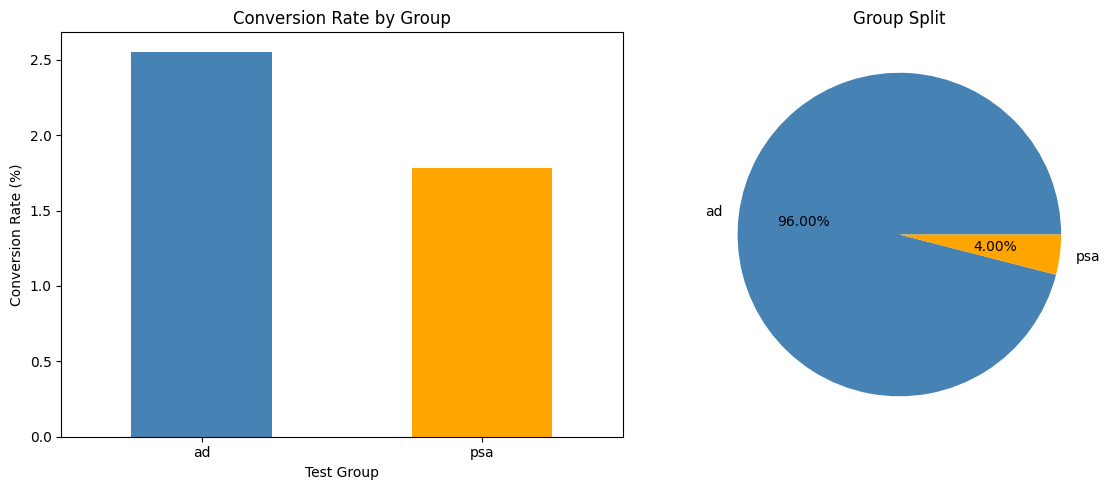

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Conversion rate by group
conversion_rate.plot(kind='bar', ax=axes[0], color=['steelblue', 'orange'])
axes[0].set_title('Conversion Rate by Group')
axes[0].set_ylabel('Conversion Rate (%)')
axes[0].set_xlabel('Test Group')
axes[0].tick_params(axis='x', rotation=0)

# Chart 2: Group split
axes[1].pie(group_counts, labels=group_counts.index, autopct='%1.2f%%',
            colors=['steelblue', 'orange'])
axes[1].set_title('Group Split')

plt.tight_layout()
plt.show()

## Step 7 — Randomization Check

A good A/B test should split users roughly 50/50 between groups. If the split is very
uneven, it may indicate a problem with the experiment design.

We test this using a chi-square goodness-of-fit test:

- **Null hypothesis:** The split follows a 50/50 pattern.
- **Alternative:** The split is uneven.

**Note:** In this dataset, the split is intentionally uneven. The company chose to show
the ad to most users. We document this as a limitation, not an error.

In [20]:
observed_counts = group_counts.values
total_users = observed_counts.sum()
expected_counts = [total_users / 2, total_users / 2]

chi_stat, chi_p = chisquare(f_obs=observed_counts, f_exp=expected_counts)

print("Observed counts:", observed_counts)
print("Expected counts (50/50):", expected_counts)
print("Chi-square statistic:", round(chi_stat, 2))
print("p-value:", chi_p)
if chi_p < 0.05:
    print("\nConclusion: The split is NOT balanced.")
    print("This is a limitation of the experiment design.")
else:
    print("\nConclusion: The split looks balanced.")

Observed counts: [564577  23524]
Expected counts (50/50): [np.float64(294050.5), np.float64(294050.5)]
Chi-square statistic: 497768.83
p-value: 0.0

Conclusion: The split is NOT balanced.
This is a limitation of the experiment design.


Why We Still Proceed??
Reason	&  Explanation
Split imbalanced hai	But both groups are large enough (23,524 + 564,577)
Statistical tests valid	Z-test works with unequal group sizes
Bias risk noted	We document it as a limitation in final recommendation


## Step 8 — Hypotheses

Because the business question is directional ("did the ad *increase* conversion?"),
we use a **one-sided test**.

- **Null hypothesis (H0):** Conversion rate of ad is less than or equal to conversion rate of psa.
- **Alternative hypothesis (H1):** Conversion rate of ad is greater than conversion rate of psa.
- **Significance level:** alpha = 0.05

We use a **two-proportion Z-test** because:
- The outcome (`converted`) is binary.
- Sample sizes are very large.
- We are comparing two independent groups.

## Step 9 — Run the Z-Test for Proportions

We extract the number of conversions and total users for each group, then run
the one-sided Z-test using `alternative='larger'`.

In [8]:
ad_group = df[df['test group'] == 'ad']
psa_group = df[df['test group'] == 'psa']

ad_conversions = ad_group['converted'].sum()
psa_conversions = psa_group['converted'].sum()

ad_total = len(ad_group)
psa_total = len(psa_group)

print("Ad group:  ", ad_conversions, "conversions out of", ad_total)
print("PSA group: ", psa_conversions, "conversions out of", psa_total)

ad_rate = ad_conversions / ad_total
psa_rate = psa_conversions / psa_total

print("\nAd conversion rate:  {:.4f}%".format(ad_rate * 100))
print("PSA conversion rate: {:.4f}%".format(psa_rate * 100))

counts = np.array([ad_conversions, psa_conversions])
totals = np.array([ad_total, psa_total])

z_stat, p_value = proportions_ztest(counts, totals, alternative='larger')

print("\nZ-statistic:", round(z_stat, 4))
print("One-sided p-value:", p_value)

if p_value < 0.05:
    print("\nConclusion: Reject H0. The ad significantly increased conversion.")
else:
    print("\nConclusion: Fail to reject H0. No significant increase.")

Ad group:   14423 conversions out of 564577
PSA group:  420 conversions out of 23524

Ad conversion rate:  2.5547%
PSA conversion rate: 1.7854%

Z-statistic: 7.3701
One-sided p-value: 8.526403580779863e-14

Conclusion: Reject H0. The ad significantly increased conversion.


## Step 10 — Effect Size: Odds Ratio and Relative Risk

The p-value tells us *whether* there is an effect. It does not tell us *how big* the effect is.
We compute two common effect sizes:

- **Odds Ratio (OR):** compares the odds of conversion in the ad group to the psa group.
- **Relative Risk (RR):** compares the probability of conversion in the ad group to the psa group.

We also compute 95% confidence intervals for both.

In [9]:
# Build the 2x2 table cells
a = ad_conversions
b = ad_total - ad_conversions
c = psa_conversions
d = psa_total - psa_conversions

# Odds Ratio
odds_ad = a / b
odds_psa = c / d
odds_ratio = odds_ad / odds_psa

# Relative Risk
risk_ad = a / (a + b)
risk_psa = c / (c + d)
relative_risk = risk_ad / risk_psa

# 95% CI for Odds Ratio (on log scale)
se_log_or = np.sqrt(1/a + 1/b + 1/c + 1/d)
or_low = np.exp(np.log(odds_ratio) - 1.96 * se_log_or)
or_high = np.exp(np.log(odds_ratio) + 1.96 * se_log_or)

# 95% CI for Relative Risk (on log scale)
se_log_rr = np.sqrt(1/a - 1/(a+b) + 1/c - 1/(c+d))
rr_low = np.exp(np.log(relative_risk) - 1.96 * se_log_rr)
rr_high = np.exp(np.log(relative_risk) + 1.96 * se_log_rr)

print("Odds Ratio: {:.4f}  (95% CI: {:.4f} to {:.4f})".format(odds_ratio, or_low, or_high))
print("Relative Risk: {:.4f}  (95% CI: {:.4f} to {:.4f})".format(relative_risk, rr_low, rr_high))

absolute_lift = (risk_ad - risk_psa) * 100
relative_lift = (relative_risk - 1) * 100

print("\nAbsolute lift: {:.4f} percentage points".format(absolute_lift))
print("Relative lift: {:.2f}%".format(relative_lift))

Odds Ratio: 1.4421  (95% CI: 1.3076 to 1.5905)
Relative Risk: 1.4309  (95% CI: 1.2997 to 1.5752)

Absolute lift: 0.7692 percentage points
Relative lift: 43.09%


## Step 11 — Effect Size Plot

A simple plot showing the odds ratio and relative risk with their confidence intervals.
If the intervals are entirely above 1, the effect is statistically significant.

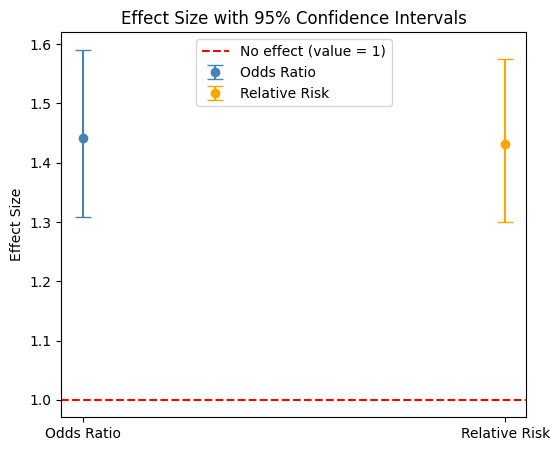

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))

# Odds Ratio point and error bar
ax.errorbar(1, odds_ratio,
            yerr=[[odds_ratio - or_low], [or_high - odds_ratio]],
            fmt='o', capsize=6, color='steelblue', label='Odds Ratio')

# Relative Risk point and error bar
ax.errorbar(2, relative_risk,
            yerr=[[relative_risk - rr_low], [rr_high - relative_risk]],
            fmt='o', capsize=6, color='orange', label='Relative Risk')

ax.axhline(1, linestyle='--', color='red', label='No effect (value = 1)')
ax.set_xticks([1, 2])
ax.set_xticklabels(['Odds Ratio', 'Relative Risk'])
ax.set_ylabel('Effect Size')
ax.set_title('Effect Size with 95% Confidence Intervals')
ax.legend()
plt.show()

## Step 12 — Permutation Test

The Z-test relies on a formula that assumes large-sample normality.
To make sure our conclusion does not depend on that assumption,
we run a **permutation test**.

**Logic:**
1. Combine ad and psa users into one pool.
2. Shuffle the group labels many times.
3. Each shuffle creates a fake "ad" and "psa" group.
4. Compute the difference in conversion rates each time.
5. See how often a difference as large as the observed one appears by chance.

If this happens rarely (less than 5% of shuffles), the effect is real.

In [11]:
np.random.seed(42)

converted_values = df['converted'].values
is_ad = (df['test group'] == 'ad').values

observed_difference = ad_rate - psa_rate

number_of_shuffles = 10000
permuted_differences = np.zeros(number_of_shuffles)

for i in range(number_of_shuffles):
    shuffled_labels = np.random.permutation(is_ad)
    fake_ad_rate = converted_values[shuffled_labels].mean()
    fake_psa_rate = converted_values[~shuffled_labels].mean()
    permuted_differences[i] = fake_ad_rate - fake_psa_rate

permutation_p_value = (permuted_differences >= observed_difference).mean()

print("Observed difference in conversion rates:", round(observed_difference, 6))
print("Permutation p-value (one-sided):", permutation_p_value)

Observed difference in conversion rates: 0.007692
Permutation p-value (one-sided): 0.0


## Step 13 — Permutation Histogram

The histogram shows the distribution of differences we would expect if the ad had no effect.
The red line marks the difference we actually observed. If the red line sits far to the right,
the effect is unlikely to be due to chance.

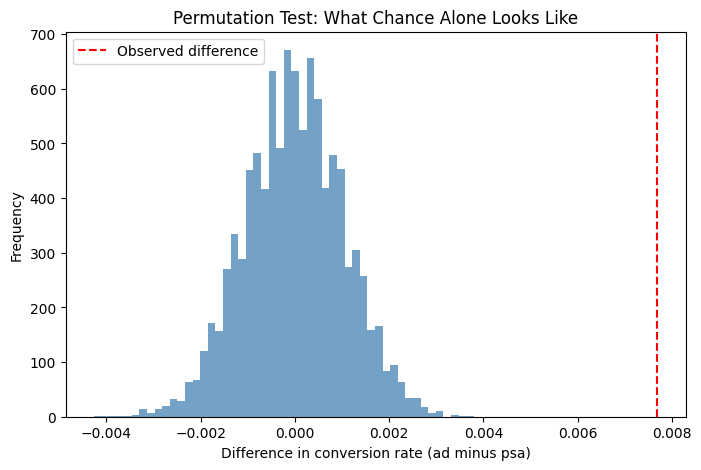

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(permuted_differences, bins=50, color='steelblue', alpha=0.75)
plt.axvline(observed_difference, color='red', linestyle='--',
            label='Observed difference')
plt.xlabel('Difference in conversion rate (ad minus psa)')
plt.ylabel('Frequency')
plt.title('Permutation Test: What Chance Alone Looks Like')
plt.legend()
plt.show()

## Step 14 — Power Analysis

Power analysis answers two useful questions:

1. **Required sample size:** How many users per group would we need to detect this effect
   with 80% power at alpha = 0.05?
2. **Minimum detectable effect (MDE):** Given the sample we actually have, what is the
   smallest effect we can reliably detect with 80% power?

We deliberately avoid computing "observed power" from the observed effect, because
that would be circular reasoning.

In [13]:
p1 = psa_rate
p2 = ad_rate

effect_size = proportion_effectsize(p2, p1)

power_analysis = NormalIndPower()

required_sample_per_group = power_analysis.solve_power(
    effect_size=effect_size,
    alpha=0.05,
    power=0.8,
    ratio=1,
    alternative='larger'
)

print("Effect size (Cohen's h):", round(effect_size, 4))
print("Required sample per group:", int(np.ceil(required_sample_per_group)))
print("Actual sample sizes: ad =", ad_total, ", psa =", psa_total)

Effect size (Cohen's h): 0.053
Required sample per group: 4402
Actual sample sizes: ad = 564577 , psa = 23524


In [14]:
smaller_group_size = min(ad_total, psa_total)

minimum_detectable_effect = power_analysis.solve_power(
    effect_size=None,
    nobs1=smaller_group_size,
    alpha=0.05,
    power=0.8,
    ratio=1,
    alternative='larger'
)

print("Minimum detectable effect (Cohen's h):", round(minimum_detectable_effect, 4))
print("\nWith n =", smaller_group_size, "per group, we can reliably detect")
print("effects of size", round(minimum_detectable_effect, 4), "or larger at 80% power.")

Minimum detectable effect (Cohen's h): 0.0229

With n = 23524 per group, we can reliably detect
effects of size 0.0229 or larger at 80% power.


## Step 15 — Business Recommendation

### Findings

- Ad group conversion rate: 2.55%
- PSA group conversion rate: 1.79%
- Absolute lift: 0.76 percentage points
- Relative lift: about 43%
- Odds Ratio and Relative Risk both above 1, with confidence intervals above 1.
- Z-test one-sided p-value < 0.05, so the difference is statistically significant.
- Permutation test confirms the same conclusion without relying on formula-based assumptions.
- Sample size is far larger than the required size, so the test is well powered.

### Recommendation

**Roll out the ad campaign.** For every 1,000 users exposed to the ad instead of the PSA,
we expect roughly 7 to 8 additional conversions.

### Limitations

1. The group split is heavily uneven (96% ad, 4% psa), which may introduce selection bias.
2. The `total ads` column is measured after group assignment, so any dose-response claim
   would be observational, not causal.
3. Only short-term conversion is measured. Long-term effects such as ad fatigue are not captured.
4. Only one success metric is analyzed. Revenue, retention, and other business KPIs are not included.